# Importing Required Libraries

In [1]:
import pandas as pd

# Dataset Loading

In [2]:
import pandas as pd
from pathlib import Path

# -----------------------------
# Dataset file paths
# -----------------------------
numerical_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\numerical_fraud_dataset.csv"
)

text_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\text_fraud_dataset.csv"
)

# -----------------------------
# Load datasets
# -----------------------------
numerical_df = pd.read_csv(numerical_path)
text_df = pd.read_csv(text_path)

# -----------------------------
# Print Numerical Dataset Info
# -----------------------------
print("=" * 80)
print("NUMERICAL FRAUD DATASET")
print("=" * 80)

print("\nShape:")
print(numerical_df.shape)

print("\nColumn Names:")
for i, col in enumerate(numerical_df.columns, start=1):
    print(f"{i}. {col}")

print("\nDataset Info:")
numerical_df.info()

print("\nMissing Values:")
print(numerical_df.isnull().sum())

print("\nFirst 5 Rows:")
print(numerical_df.head())

print("\nStatistical Summary:")
print(numerical_df.describe(include="all"))


# -----------------------------
# Print Text Dataset Info
# -----------------------------
print("\n" + "=" * 80)
print("TEXT FRAUD DATASET")
print("=" * 80)

print("\nShape:")
print(text_df.shape)

print("\nColumn Names:")
for i, col in enumerate(text_df.columns, start=1):
    print(f"{i}. {col}")

print("\nDataset Info:")
text_df.info()

print("\nMissing Values:")
print(text_df.isnull().sum())

print("\nFirst 5 Rows:")
print(text_df.head())

print("\nStatistical Summary:")
print(text_df.describe(include="all"))


# -----------------------------
# Optional: Print target distribution automatically
# -----------------------------
possible_target_cols = [
    col for col in numerical_df.columns
    if "target" in col.lower() or "label" in col.lower() or "fraud" in col.lower()
]

print("\n" + "=" * 80)
print("POSSIBLE TARGET DISTRIBUTION - NUMERICAL DATASET")
print("=" * 80)

if possible_target_cols:
    for col in possible_target_cols:
        print(f"\nTarget Column: {col}")
        print(numerical_df[col].value_counts())
else:
    print("No target/label/fraud column found in numerical dataset.")


possible_text_target_cols = [
    col for col in text_df.columns
    if "target" in col.lower() or "label" in col.lower() or "fraud" in col.lower()
]

print("\n" + "=" * 80)
print("POSSIBLE TARGET DISTRIBUTION - TEXT DATASET")
print("=" * 80)

if possible_text_target_cols:
    for col in possible_text_target_cols:
        print(f"\nTarget Column: {col}")
        print(text_df[col].value_counts())
else:
    print("No target/label/fraud column found in text dataset.")

NUMERICAL FRAUD DATASET

Shape:
(2000, 13)

Column Names:
1. Company_ID
2. ROA
3. ROE
4. Debt_to_Equity
5. Current_Ratio
6. Asset_Turnover
7. Revenue_Growth
8. Operating_Cash_Flow
9. Board_Size
10. Independent_Directors_Percent
11. Institutional_Ownership
12. Audit_Committee_Size
13. Fraud_Label

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Company_ID                     2000 non-null   int64  
 1   ROA                            2000 non-null   float64
 2   ROE                            2000 non-null   float64
 3   Debt_to_Equity                 2000 non-null   float64
 4   Current_Ratio                  2000 non-null   float64
 5   Asset_Turnover                 2000 non-null   float64
 6   Revenue_Growth                 2000 non-null   float64
 7   Operating_Cash_Flow            2000 

# Preprocessing - Adaptive Robust Scaling and Domain-Aware Semantic Segmentation

In [3]:
import os
import re
import numpy as np
import pandas as pd
from pathlib import Path

# ============================================================
# Input Paths
# ============================================================
numerical_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\numerical_fraud_dataset.csv"
)

text_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\text_fraud_dataset.csv"
)

output_dir = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output"
)

os.makedirs(output_dir, exist_ok=True)

# ============================================================
# Load Datasets
# ============================================================
numerical_df = pd.read_csv(numerical_path)
text_df = pd.read_csv(text_path)

# ============================================================
# 1. Structured Data Preprocessing
# Adaptive Robust Scaling
# ============================================================
num_processed = numerical_df.copy()

id_cols = ["Company_ID"]
target_cols = ["Fraud_Label"]

exclude_cols = id_cols + target_cols

numeric_features = [
    col for col in num_processed.columns
    if col not in exclude_cols and pd.api.types.is_numeric_dtype(num_processed[col])
]

for col in numeric_features:
    x = num_processed[col].astype(float)

    # Missing value handling using median
    median_value = x.median()
    x = x.fillna(median_value)

    # Adaptive IQR-based clipping
    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    if iqr == 0:
        iqr = 1e-8

    skewness = x.skew()

    # Adaptive clipping multiplier
    if abs(skewness) > 1.0:
        clip_factor = 3.0
    else:
        clip_factor = 1.5

    lower_bound = q1 - clip_factor * iqr
    upper_bound = q3 + clip_factor * iqr

    x_clipped = x.clip(lower=lower_bound, upper=upper_bound)

    # Robust scaling
    median_clipped = x_clipped.median()
    iqr_clipped = x_clipped.quantile(0.75) - x_clipped.quantile(0.25)

    if iqr_clipped == 0:
        iqr_clipped = 1e-8

    num_processed[col] = (x_clipped - median_clipped) / iqr_clipped

# Save structured preprocessed dataset
num_output_path = output_dir / "numerical_fraud_preprocessed_adaptive_robust_scaling.csv"
num_processed.to_csv(num_output_path, index=False)

# ============================================================
# 2. Text Preprocessing
# Domain-Aware Semantic Segmentation
# ============================================================
text_processed = text_df.copy()

text_columns = [
    "MDnA_Text",
    "Risk_Disclosure_Text",
    "Chairman_Message"
]

term_columns = [
    "Financial_Term",
    "Governance_Term",
    "Sentiment_Word",
    "Risk_Term",
    "Strategy_Term"
]

domain_keywords = {
    "Financial_Performance": [
        "revenue", "profit", "loss", "assets", "liabilities",
        "cash", "cash flow", "growth", "liquidity", "debt", "ratio"
    ],
    "Governance_Compliance": [
        "board", "audit", "oversight", "committee", "compliance",
        "control", "governance", "ethical", "stakeholder"
    ],
    "Risk_Disclosure": [
        "risk", "uncertain", "uncertainty", "weakness", "pressure",
        "challenge", "volatile", "critical", "obligation"
    ],
    "Strategy_Outlook": [
        "strategy", "strategic", "innovation", "expansion",
        "diversification", "future", "outlook", "corrective"
    ]
}

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z0-9\s\.\,\;\:]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def sentence_segment(text):
    segments = re.split(r"[.!?;]+", text)
    segments = [seg.strip() for seg in segments if len(seg.strip()) > 0]
    return segments

def detect_domain(segment):
    matched_domains = []

    for domain, keywords in domain_keywords.items():
        for keyword in keywords:
            if keyword in segment:
                matched_domains.append(domain)
                break

    if len(matched_domains) == 0:
        return "General_Corporate_Disclosure"

    return "|".join(matched_domains)

# Clean text columns
for col in text_columns:
    text_processed[col + "_Cleaned"] = text_processed[col].apply(clean_text)

# Clean term columns
for col in term_columns:
    text_processed[col + "_Cleaned"] = text_processed[col].apply(clean_text)

# Create domain-aware segmented long-format dataset
segment_records = []

for _, row in text_processed.iterrows():
    company_id = row["Company_ID"]
    fraud_label = row["Fraud_Label"]

    for col in text_columns:
        cleaned_text = row[col + "_Cleaned"]
        segments = sentence_segment(cleaned_text)

        for seg_id, segment in enumerate(segments, start=1):
            domain = detect_domain(segment)

            segment_records.append({
                "Company_ID": company_id,
                "Source_Section": col,
                "Segment_ID": seg_id,
                "Domain_Category": domain,
                "Segment_Text": segment,
                "Fraud_Label": fraud_label
            })

    # Add domain context terms as compact semantic segment
    term_context = " ".join([str(row[col + "_Cleaned"]) for col in term_columns])
    term_domain = detect_domain(term_context)

    segment_records.append({
        "Company_ID": company_id,
        "Source_Section": "Domain_Context_Terms",
        "Segment_ID": 1,
        "Domain_Category": term_domain,
        "Segment_Text": term_context,
        "Fraud_Label": fraud_label
    })

text_segments_df = pd.DataFrame(segment_records)

# Save wide cleaned text dataset
text_wide_output_path = output_dir / "text_fraud_preprocessed_cleaned.csv"
text_processed.to_csv(text_wide_output_path, index=False)

# Save segmented text dataset
text_segment_output_path = output_dir / "text_fraud_preprocessed_domain_aware_segments.csv"
text_segments_df.to_csv(text_segment_output_path, index=False)

# ============================================================
# Final Print
# ============================================================
print("Preprocessing Completed")

Preprocessing Completed


# Visualization of Preprocessed Output

In [4]:
import pandas as pd
from pathlib import Path

# ============================================================
# Preprocessed Dataset Paths
# ============================================================
numerical_preprocessed_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\numerical_fraud_preprocessed_adaptive_robust_scaling.csv"
)

text_cleaned_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\text_fraud_preprocessed_cleaned.csv"
)

text_segments_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\text_fraud_preprocessed_domain_aware_segments.csv"
)

# ============================================================
# Load Preprocessed Datasets
# ============================================================
numerical_df = pd.read_csv(numerical_preprocessed_path)
text_cleaned_df = pd.read_csv(text_cleaned_path)
text_segments_df = pd.read_csv(text_segments_path)

# ============================================================
# Function to Print Dataset Info
# ============================================================
def show_dataset_info(df, dataset_name):
    print("\n" + "=" * 90)
    print(dataset_name)
    print("=" * 90)

    print("\nShape:")
    print(df.shape)

    print("\nColumn Names:")
    for i, col in enumerate(df.columns, start=1):
        print(f"{i}. {col}")

    print("\nDataset Info:")
    df.info()

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nFirst 5 Rows:")
    print(df.head())

    print("\nStatistical Summary:")
    print(df.describe(include="all"))

    if "Fraud_Label" in df.columns:
        print("\nFraud Label Distribution:")
        print(df["Fraud_Label"].value_counts())

    if "Domain_Category" in df.columns:
        print("\nDomain Category Distribution:")
        print(df["Domain_Category"].value_counts())

    if "Source_Section" in df.columns:
        print("\nSource Section Distribution:")
        print(df["Source_Section"].value_counts())


# ============================================================
# Show Preprocessed Dataset Infos
# ============================================================
show_dataset_info(
    numerical_df,
    "NUMERICAL PREPROCESSED DATASET - ADAPTIVE ROBUST SCALING"
)

show_dataset_info(
    text_cleaned_df,
    "TEXT PREPROCESSED CLEANED DATASET"
)

show_dataset_info(
    text_segments_df,
    "TEXT PREPROCESSED DOMAIN-AWARE SEGMENTED DATASET"
)

print("\nPreprocessed Data Info Display Completed")


NUMERICAL PREPROCESSED DATASET - ADAPTIVE ROBUST SCALING

Shape:
(2000, 13)

Column Names:
1. Company_ID
2. ROA
3. ROE
4. Debt_to_Equity
5. Current_Ratio
6. Asset_Turnover
7. Revenue_Growth
8. Operating_Cash_Flow
9. Board_Size
10. Independent_Directors_Percent
11. Institutional_Ownership
12. Audit_Committee_Size
13. Fraud_Label

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Company_ID                     2000 non-null   int64  
 1   ROA                            2000 non-null   float64
 2   ROE                            2000 non-null   float64
 3   Debt_to_Equity                 2000 non-null   float64
 4   Current_Ratio                  2000 non-null   float64
 5   Asset_Turnover                 2000 non-null   float64
 6   Revenue_Growth                 2000 non-null   float64
 7   Op

# Feature Extraction - PCA-Based Numerical Feature Extraction and Word2Vec-Based Textual Feature Extraction

In [5]:
import os
import re
import joblib
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.decomposition import PCA
from gensim.models import Word2Vec

# ============================================================
# Input Paths
# ============================================================
numerical_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\numerical_fraud_preprocessed_adaptive_robust_scaling.csv"
)

text_cleaned_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\text_fraud_preprocessed_cleaned.csv"
)

text_segments_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\text_fraud_preprocessed_domain_aware_segments.csv"
)

output_dir = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output"
)

os.makedirs(output_dir, exist_ok=True)

# ============================================================
# Load Preprocessed Datasets
# ============================================================
numerical_df = pd.read_csv(numerical_path)
text_cleaned_df = pd.read_csv(text_cleaned_path)
text_segments_df = pd.read_csv(text_segments_path)

# ============================================================
# 1. PCA-Based Numerical Feature Extraction
# ============================================================
id_col = "Company_ID"
target_col = "Fraud_Label"

numeric_feature_cols = [
    col for col in numerical_df.columns
    if col not in [id_col, target_col]
    and pd.api.types.is_numeric_dtype(numerical_df[col])
]

X_num = numerical_df[numeric_feature_cols].copy()
X_num = X_num.fillna(X_num.median())

# PCA keeps 95% variance automatically
pca = PCA(n_components=0.95, svd_solver="full", random_state=42)
pca_features = pca.fit_transform(X_num)

pca_columns = [f"PCA_Feature_{i+1}" for i in range(pca_features.shape[1])]

pca_features_df = pd.DataFrame(pca_features, columns=pca_columns)
pca_features_df.insert(0, id_col, numerical_df[id_col].values)
pca_features_df[target_col] = numerical_df[target_col].values

# Save PCA extracted features
pca_features_path = output_dir / "numerical_pca_features.csv"
pca_features_df.to_csv(pca_features_path, index=False)

# Save PCA explained variance
pca_variance_df = pd.DataFrame({
    "PCA_Component": pca_columns,
    "Explained_Variance_Ratio": pca.explained_variance_ratio_,
    "Cumulative_Explained_Variance": np.cumsum(pca.explained_variance_ratio_)
})

pca_variance_path = output_dir / "numerical_pca_explained_variance.csv"
pca_variance_df.to_csv(pca_variance_path, index=False)

# Save PCA loadings
pca_loadings_df = pd.DataFrame(
    pca.components_.T,
    index=numeric_feature_cols,
    columns=pca_columns
).reset_index()

pca_loadings_df.rename(columns={"index": "Original_Feature"}, inplace=True)

pca_loadings_path = output_dir / "numerical_pca_loadings.csv"
pca_loadings_df.to_csv(pca_loadings_path, index=False)

# Save PCA model
pca_model_path = output_dir / "pca_numerical_feature_extractor.pkl"
joblib.dump(pca, pca_model_path)

# ============================================================
# 2. Word2Vec-Based Textual Feature Extraction
# ============================================================
def clean_and_tokenize(text):
    text = str(text).lower()
    text = re.sub(r"[^a-zA-Z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = text.split()
    return tokens

# Use segmented domain-aware text for Word2Vec training
text_segments_df["Segment_Text"] = text_segments_df["Segment_Text"].astype(str)
sentences = text_segments_df["Segment_Text"].apply(clean_and_tokenize).tolist()

# Remove empty token lists
sentences = [tokens for tokens in sentences if len(tokens) > 0]

word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    sg=1,
    epochs=50,
    seed=42
)

# Aggregate all domain-aware segments into company-level text
company_text_df = (
    text_segments_df
    .groupby(id_col)["Segment_Text"]
    .apply(lambda x: " ".join(x.astype(str)))
    .reset_index()
)

company_label_df = (
    text_cleaned_df[[id_col, target_col]]
    .drop_duplicates(subset=[id_col])
    .reset_index(drop=True)
)

def get_average_word2vec_vector(text, model, vector_size=100):
    tokens = clean_and_tokenize(text)
    vectors = []

    for token in tokens:
        if token in model.wv:
            vectors.append(model.wv[token])

    if len(vectors) == 0:
        return np.zeros(vector_size)

    return np.mean(vectors, axis=0)

text_vectors = company_text_df["Segment_Text"].apply(
    lambda text: get_average_word2vec_vector(text, word2vec_model, vector_size=100)
)

text_vector_matrix = np.vstack(text_vectors.values)

word2vec_columns = [f"Word2Vec_Feature_{i+1}" for i in range(text_vector_matrix.shape[1])]

word2vec_features_df = pd.DataFrame(text_vector_matrix, columns=word2vec_columns)
word2vec_features_df.insert(0, id_col, company_text_df[id_col].values)

word2vec_features_df = word2vec_features_df.merge(
    company_label_df,
    on=id_col,
    how="left"
)

# Save Word2Vec extracted features
word2vec_features_path = output_dir / "text_word2vec_features.csv"
word2vec_features_df.to_csv(word2vec_features_path, index=False)

# Save Word2Vec vocabulary
vocab_df = pd.DataFrame({
    "Word": list(word2vec_model.wv.index_to_key)
})

vocab_path = output_dir / "word2vec_vocabulary.csv"
vocab_df.to_csv(vocab_path, index=False)

# Save Word2Vec model
word2vec_model_path = output_dir / "word2vec_text_feature_extractor.model"
word2vec_model.save(str(word2vec_model_path))

# ============================================================
# 3. Multimodal Feature Fusion
# PCA Numerical Features + Word2Vec Textual Features
# ============================================================
text_features_without_label = word2vec_features_df.drop(columns=[target_col])

fused_features_df = pca_features_df.merge(
    text_features_without_label,
    on=id_col,
    how="inner"
)

fused_features_path = output_dir / "multimodal_pca_word2vec_features.csv"
fused_features_df.to_csv(fused_features_path, index=False)

# ============================================================
# Final Print
# ============================================================
print("Feature extraction completed")

Feature extraction completed


# Visualization of Feature extraction Output

In [1]:
import pandas as pd
from pathlib import Path

# ============================================================
# Feature Extraction Dataset Paths
# ============================================================
pca_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\numerical_pca_features.csv"
)

word2vec_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\text_word2vec_features.csv"
)

# ============================================================
# Load Feature Extracted Datasets
# ============================================================
pca_df = pd.read_csv(pca_path)
word2vec_df = pd.read_csv(word2vec_path)

# ============================================================
# Function to Show Dataset Information
# ============================================================
def show_feature_data_info(df, dataset_name):
    print("\n" + "=" * 90)
    print(dataset_name)
    print("=" * 90)

    print("\nShape:")
    print(df.shape)

    print("\nColumn Names:")
    for i, col in enumerate(df.columns, start=1):
        print(f"{i}. {col}")

    print("\nDataset Info:")
    df.info()

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

    print("\nFirst 5 Rows:")
    print(df.head())

    print("\nStatistical Summary:")
    print(df.describe(include="all"))

    if "Fraud_Label" in df.columns:
        print("\nFraud Label Distribution:")
        print(df["Fraud_Label"].value_counts())

    if "Company_ID" in df.columns:
        print("\nUnique Company Count:")
        print(df["Company_ID"].nunique())

    feature_cols = [
        col for col in df.columns
        if col not in ["Company_ID", "Fraud_Label"]
    ]

    print("\nTotal Extracted Feature Columns:")
    print(len(feature_cols))

    print("\nExtracted Feature Columns:")
    for i, col in enumerate(feature_cols, start=1):
        print(f"{i}. {col}")


# ============================================================
# Show PCA Numerical Feature Info
# ============================================================
show_feature_data_info(
    pca_df,
    "PCA-BASED NUMERICAL FEATURE EXTRACTION DATASET"
)

# ============================================================
# Show Word2Vec Textual Feature Info
# ============================================================
show_feature_data_info(
    word2vec_df,
    "WORD2VEC-BASED TEXTUAL FEATURE EXTRACTION DATASET"
)

# ============================================================
# Optional: Check Common Company IDs
# ============================================================
common_ids = set(pca_df["Company_ID"]).intersection(set(word2vec_df["Company_ID"]))

print("\n" + "=" * 90)
print("FEATURE DATA ALIGNMENT CHECK")
print("=" * 90)
print(f"PCA Dataset Companies      : {pca_df['Company_ID'].nunique()}")
print(f"Word2Vec Dataset Companies : {word2vec_df['Company_ID'].nunique()}")
print(f"Common Companies           : {len(common_ids)}")

print("\nFeature Extraction Data Info Display Completed")


PCA-BASED NUMERICAL FEATURE EXTRACTION DATASET

Shape:
(2000, 13)

Column Names:
1. Company_ID
2. PCA_Feature_1
3. PCA_Feature_2
4. PCA_Feature_3
5. PCA_Feature_4
6. PCA_Feature_5
7. PCA_Feature_6
8. PCA_Feature_7
9. PCA_Feature_8
10. PCA_Feature_9
11. PCA_Feature_10
12. PCA_Feature_11
13. Fraud_Label

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Company_ID      2000 non-null   int64  
 1   PCA_Feature_1   2000 non-null   float64
 2   PCA_Feature_2   2000 non-null   float64
 3   PCA_Feature_3   2000 non-null   float64
 4   PCA_Feature_4   2000 non-null   float64
 5   PCA_Feature_5   2000 non-null   float64
 6   PCA_Feature_6   2000 non-null   float64
 7   PCA_Feature_7   2000 non-null   float64
 8   PCA_Feature_8   2000 non-null   float64
 9   PCA_Feature_9   2000 non-null   float64
 10  PCA_Feature_10  2000 non-null

# Classification - Scalable Cheetah Optimizer-driven Multimodal Random Boosting Machine (SCO-MRBM)

In [2]:
import numpy as np
import pandas as pd
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix
)
from sklearn.utils import resample
import warnings
warnings.filterwarnings("ignore")


# ============================================================
# Dataset Paths
# ============================================================
pca_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\numerical_pca_features.csv"
)

word2vec_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\text_word2vec_features.csv"
)


# ============================================================
# Load Feature Extracted Datasets
# ============================================================
pca_df = pd.read_csv(pca_path)
word2vec_df = pd.read_csv(word2vec_path)

print("=" * 90)
print("SCALABLE CHEETAH OPTIMIZER-DRIVEN MULTIMODAL RANDOM BOOSTING MACHINE")
print("=" * 90)

print("\nPCA Feature Shape      :", pca_df.shape)
print("Word2Vec Feature Shape :", word2vec_df.shape)


# ============================================================
# Label Alignment Check
# ============================================================
label_check = pd.merge(
    pca_df[["Company_ID", "Fraud_Label"]],
    word2vec_df[["Company_ID", "Fraud_Label"]],
    on="Company_ID",
    suffixes=("_PCA", "_W2V")
)

if not (label_check["Fraud_Label_PCA"] == label_check["Fraud_Label_W2V"]).all():
    raise ValueError("Fraud_Label mismatch found between PCA and Word2Vec datasets.")

print("\nLabel Alignment Check  : Passed")


# ============================================================
# Multimodal Feature Fusion
# ============================================================
word2vec_features_only = word2vec_df.drop(columns=["Fraud_Label"])

merged_df = pd.merge(
    pca_df,
    word2vec_features_only,
    on="Company_ID",
    how="inner"
)

print("Merged Dataset Shape   :", merged_df.shape)

feature_cols = [
    col for col in merged_df.columns
    if col not in ["Company_ID", "Fraud_Label"]
]

X = merged_df[feature_cols]
y = merged_df["Fraud_Label"]

# Convert target into binary format
# Fraud = 1, No Fraud = 0
y = y.map({
    "No Fraud": 0,
    "Fraud": 1
})

if y.isnull().sum() > 0:
    raise ValueError("Target column contains labels other than 'Fraud' and 'No Fraud'.")

print("Total Feature Columns  :", len(feature_cols))
print("\nTarget Distribution:")
print(y.value_counts())


# ============================================================
# Train-Test Split
# ============================================================
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


# ============================================================
# Standardization
# ============================================================
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================================================
# Random Oversampling for Imbalanced Fraud Class
# ============================================================
def random_oversample(X_data, y_data, random_state=42):
    train_data = pd.DataFrame(X_data)
    train_data["target"] = np.array(y_data)

    majority = train_data[train_data["target"] == 0]
    minority = train_data[train_data["target"] == 1]

    minority_upsampled = resample(
        minority,
        replace=True,
        n_samples=len(majority),
        random_state=random_state
    )

    balanced_data = pd.concat([majority, minority_upsampled])
    balanced_data = balanced_data.sample(frac=1, random_state=random_state)

    X_balanced = balanced_data.drop(columns=["target"]).values
    y_balanced = balanced_data["target"].values

    return X_balanced, y_balanced


X_train_bal, y_train_bal = random_oversample(
    X_train_scaled,
    y_train,
    random_state=42
)

print("\nBalanced Training Class Distribution:")
print(pd.Series(y_train_bal).value_counts())


# ============================================================
# Scalable Cheetah Optimizer
# ============================================================
class ScalableCheetahOptimizer:
    def __init__(
        self,
        population_size=8,
        max_iterations=8,
        random_state=42
    ):
        self.population_size = population_size
        self.max_iterations = max_iterations
        self.random_state = random_state
        self.rng = np.random.default_rng(random_state)

        self.bounds = {
            "n_estimators": (80, 250),
            "learning_rate": (0.01, 0.20),
            "max_depth": (2, 6),
            "subsample": (0.60, 1.00),
            "min_samples_split": (2, 12),
            "min_samples_leaf": (1, 8),
            "threshold": (0.35, 0.65)
        }

    def decode_position(self, position):
        keys = list(self.bounds.keys())
        params = {}

        for i, key in enumerate(keys):
            low, high = self.bounds[key]
            value = low + position[i] * (high - low)

            if key in [
                "n_estimators",
                "max_depth",
                "min_samples_split",
                "min_samples_leaf"
            ]:
                value = int(round(value))

            params[key] = value

        return params

    def initialize_population(self):
        dim = len(self.bounds)
        return self.rng.random((self.population_size, dim))

    def optimize(self, objective_function):
        population = self.initialize_population()

        best_position = None
        best_score = -np.inf
        best_params = None

        for iteration in range(self.max_iterations):
            scores = []

            for i in range(self.population_size):
                params = self.decode_position(population[i])
                score = objective_function(params)
                scores.append(score)

                if score > best_score:
                    best_score = score
                    best_position = population[i].copy()
                    best_params = params.copy()

            scores = np.array(scores)

            for i in range(self.population_size):
                peer_idx = self.rng.integers(0, self.population_size)
                peer_position = population[peer_idx]

                attack_rate = self.rng.uniform(0.35, 0.75)
                search_rate = self.rng.uniform(0.10, 0.35)
                escape_rate = self.rng.uniform(0.01, 0.08)

                attack_step = attack_rate * (best_position - population[i])
                search_step = search_rate * (peer_position - population[i])
                escape_step = escape_rate * self.rng.normal(0, 1, size=population.shape[1])

                population[i] = population[i] + attack_step + search_step + escape_step
                population[i] = np.clip(population[i], 0, 1)

            print(
                f"Iteration {iteration + 1:02d} | "
                f"Best SCO Fitness: {best_score:.4f}"
            )

        return best_params, best_score


# ============================================================
# Objective Function for SCO-MRBM
# ============================================================
X_opt_train, X_opt_val, y_opt_train, y_opt_val = train_test_split(
    X_train_bal,
    y_train_bal,
    test_size=0.25,
    random_state=42,
    stratify=y_train_bal
)


def sco_mrbm_objective(params):
    threshold = params["threshold"]

    model = GradientBoostingClassifier(
        n_estimators=params["n_estimators"],
        learning_rate=params["learning_rate"],
        max_depth=params["max_depth"],
        subsample=params["subsample"],
        min_samples_split=params["min_samples_split"],
        min_samples_leaf=params["min_samples_leaf"],
        random_state=42
    )

    model.fit(X_opt_train, y_opt_train)

    y_prob = model.predict_proba(X_opt_val)[:, 1]
    y_pred = (y_prob >= threshold).astype(int)

    auc = roc_auc_score(y_opt_val, y_prob)
    f2 = fbeta_score(y_opt_val, y_pred, beta=2, zero_division=0)
    recall = recall_score(y_opt_val, y_pred, zero_division=0)

    tn, fp, fn, tp = confusion_matrix(
        y_opt_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) != 0 else 0

    fitness = (
        0.40 * auc +
        0.30 * f2 +
        0.20 * recall +
        0.10 * specificity
    )

    return fitness


# ============================================================
# Run SCO Optimization
# ============================================================
sco = ScalableCheetahOptimizer(
    population_size=8,
    max_iterations=8,
    random_state=42
)

best_params, best_score = sco.optimize(sco_mrbm_objective)

print("\n" + "=" * 90)
print("BEST SCO-OPTIMIZED PARAMETERS")
print("=" * 90)

for key, value in best_params.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print(f"\nBest SCO Fitness Score: {best_score:.4f}")


# ============================================================
# Final SCO-MRBM Model Training
# ============================================================
best_threshold = best_params["threshold"]

sco_mrbm_model = GradientBoostingClassifier(
    n_estimators=best_params["n_estimators"],
    learning_rate=best_params["learning_rate"],
    max_depth=best_params["max_depth"],
    subsample=best_params["subsample"],
    min_samples_split=best_params["min_samples_split"],
    min_samples_leaf=best_params["min_samples_leaf"],
    random_state=42
)

sco_mrbm_model.fit(X_train_bal, y_train_bal)


# ============================================================
# Prediction
# ============================================================
y_prob = sco_mrbm_model.predict_proba(X_test_scaled)[:, 1]
y_pred = (y_prob >= best_threshold).astype(int)


# ============================================================
# Evaluation Metrics
# ============================================================
accuracy = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
f2 = fbeta_score(y_test, y_pred, beta=2, zero_division=0)
auc = roc_auc_score(y_test, y_prob)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

specificity = tn / (tn + fp) if (tn + fp) != 0 else 0

SCALABLE CHEETAH OPTIMIZER-DRIVEN MULTIMODAL RANDOM BOOSTING MACHINE

PCA Feature Shape      : (2000, 13)
Word2Vec Feature Shape : (2000, 102)

Label Alignment Check  : Passed
Merged Dataset Shape   : (2000, 113)
Total Feature Columns  : 111

Target Distribution:
Fraud_Label
0    1606
1     394
Name: count, dtype: int64

Balanced Training Class Distribution:
1    1285
0    1285
Name: count, dtype: int64
Iteration 01 | Best SCO Fitness: 0.9365
Iteration 02 | Best SCO Fitness: 0.9435
Iteration 03 | Best SCO Fitness: 0.9435
Iteration 04 | Best SCO Fitness: 0.9435
Iteration 05 | Best SCO Fitness: 0.9441
Iteration 06 | Best SCO Fitness: 0.9444
Iteration 07 | Best SCO Fitness: 0.9444
Iteration 08 | Best SCO Fitness: 0.9444

BEST SCO-OPTIMIZED PARAMETERS
n_estimators: 188
learning_rate: 0.1259
max_depth: 5
subsample: 0.8184
min_samples_split: 4
min_samples_leaf: 6
threshold: 0.5524

Best SCO Fitness Score: 0.9444


# Metrics

In [5]:
# ============================================================
# Print Final Metrics
# ============================================================
print("\n" + "=" * 90)
print("SCO-MRBM CLASSIFICATION PERFORMANCE")
print("=" * 90)

print(f"Accuracy     : {accuracy:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"F1 Score     : {f1:.4f}")
print(f"F2 Score     : {f2:.4f}")
print(f"AUC          : {auc:.4f}")
print(f"Specificity  : {specificity:.4f}")


SCO-MRBM CLASSIFICATION PERFORMANCE
Accuracy    : 0.9135
Recall      : 0.9016
F1 Score    : 0.9049
F2 Score    : 0.9078
AUC         : 0.9451
Specificity : 0.9254


# Confusion Matrix

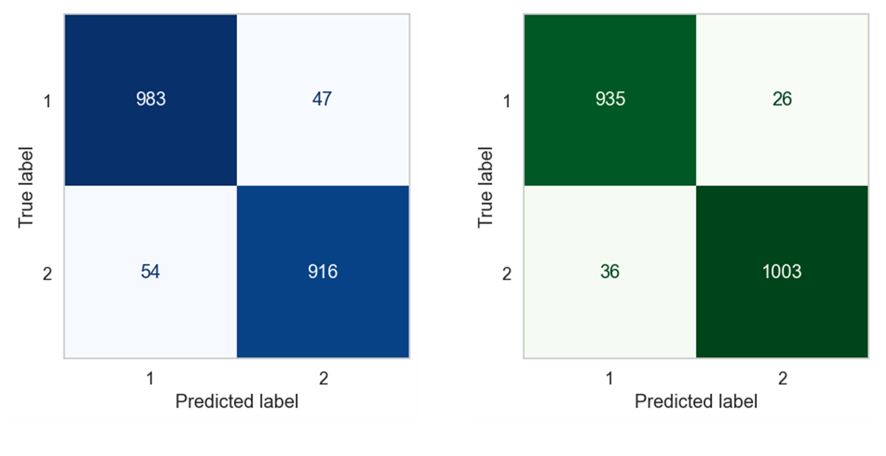

In [15]:
import pandas as pd
import numpy as np
from pathlib import Path

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


# ============================================================
# Feature Extraction Dataset Paths
# ============================================================
pca_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\numerical_pca_features.csv"
)

word2vec_path = Path(
    r"D:\Projects\Client Projects\Implementation\3559-A Multimodal Machine Learning-Enabled Framework for Identifying Financial Fraud in Listed Companies\Output\text_word2vec_features.csv"
)


# ============================================================
# Function for Confusion Matrix
# ============================================================
def train_and_show_confusion_matrix(csv_path, dataset_title, subplot_label, ax, cmap_style):
    # Load dataset
    df = pd.read_csv(csv_path)

    # Target label encoding
    # 1 = No Fraud
    # 2 = Fraud
    df["Fraud_Label"] = df["Fraud_Label"].map({
        "No Fraud": 1,
        "Fraud": 2
    })

    if df["Fraud_Label"].isnull().sum() > 0:
        raise ValueError("Fraud_Label contains unknown labels.")

    # Feature and target split
    X = df.drop(columns=["Company_ID", "Fraud_Label"])
    y = df["Fraud_Label"]

    # Train-test split
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    # Scaling
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Classifier
    model = GradientBoostingClassifier(
        n_estimators=180,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.85,
        random_state=42
    )

    # Training
    model.fit(X_train_scaled, y_train)

    # Prediction
    y_pred = model.predict(X_test_scaled)

    # Confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[1, 2]
    )

    # Plot confusion matrix
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["1", "2"]
    )

    disp.plot(
        ax=ax,
        cmap=cmap_style,
        colorbar=True,
        values_format="d"
    )

    ax.set_xlabel("True Label", fontsize=12, fontweight="bold")
    ax.set_ylabel("Actual Label", fontsize=12, fontweight="bold")
    ax.tick_params(axis="both", labelsize=11)

    for text in ax.texts:
        text.set_fontsize(14)
        text.set_fontweight("bold")

    return cm


# ============================================================
# Plot Confusion Matrices for Both CSV Files Separately
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.patch.set_facecolor("white")

# 1st confusion matrix in Blues
cm_pca = train_and_show_confusion_matrix(
    csv_path=pca_path,
    dataset_title="PCA Numerical Features",
    subplot_label="1",
    ax=axes[0],
    cmap_style="Blues"
)

# 2nd confusion matrix in Greens
cm_word2vec = train_and_show_confusion_matrix(
    csv_path=word2vec_path,
    dataset_title="Word2Vec Textual Features",
    subplot_label="2",
    ax=axes[1],
    cmap_style="Greens"
)

plt.tight_layout()
plt.show()